In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# 2. Import the Retail Sales Dataset

df = pd.read_csv("D:/Sem_7/DMV Lab/Retail_Sales_Data.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:
print("First 5 records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
print(df.info())

print("\nStatistical Summary:")
print(df.describe(include='all'))

print("\nMissing Values:")
print(df.isnull().sum())

First 5 records:
   Transaction_ID  Customer_ID State  Age Shop_Category  Sales Gender  \
0               1         1234    MP   10       Grocery     10      M   
1               2         1235    UP   21         Dairy     30      F   
2               3         1236    AP   23          Deli     23      F   
3               4         1237    RP   25          Meat     21      F   
4               5         1238    DP   27       Clothes     90      F   

   Items_in_basket  
0                2  
1                3  
2                4  
3                4  
4                3  

Dataset Shape:
(312, 8)

Column Names:
['Transaction_ID', 'Customer_ID', 'State', 'Age', 'Shop_Category', 'Sales', 'Gender', 'Items_in_basket']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 312 entries, 0 to 311
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Transaction_ID   312 non-null    int64 
 1   Custome

In [4]:
# 4. Identify Relevant Variables

print("Relevant variables for sales aggregation:")

print("\nRegion:")
print(df['State'].unique())

print("\nShop Category")
print(df['Shop_Category'].unique())

print("\nSales:")
print(df['Sales'].describe())

Relevant variables for sales aggregation:

Region:
['MP' 'UP' 'AP' 'RP' 'DP' 'KP']

Shop Category
['Grocery' 'Dairy' 'Deli' 'Meat' 'Clothes' 'Electronics']

Sales:
count    312.000000
mean     212.967949
std      140.071728
min       10.000000
25%       92.000000
50%      189.500000
75%      301.250000
max      709.000000
Name: Sales, dtype: float64


In [5]:
# 5. Group Sales Data by Region
#    Calculate Total Sales Amount for Each Region-

sales_by_region = (
    df.groupby('State')['Sales']
      .sum()
      .reset_index()
      .sort_values(by='Sales', ascending=False)
)

print("Total Sales Amount by Region:")
print(sales_by_region)

Total Sales Amount by Region:
  State  Sales
1    DP  23346
0    AP  12176
4    RP  11049
2    KP  10887
3    MP   4916
5    UP   4072


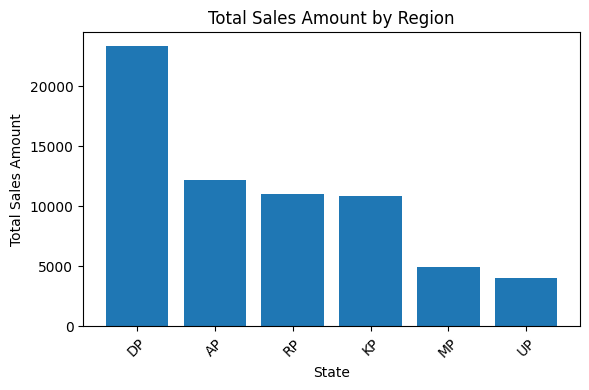

In [6]:
# 6. Visualize Sales Distribution by Region
#    Bar Plot

plt.figure(figsize=(6, 4))

plt.bar(
    sales_by_region['State'],
    sales_by_region['Sales']
)

plt.xlabel('State')
plt.ylabel('Total Sales Amount')
plt.title('Total Sales Amount by Region')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

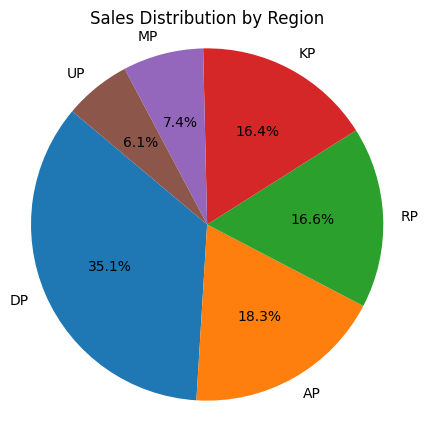

In [7]:
# 7. Pie Chart - Sales Distribution by Region

plt.figure(figsize=(5,5))

plt.pie(
    sales_by_region['Sales'],
    labels=sales_by_region['State'],
    autopct='%1.1f%%',
    startangle=140
)

plt.title('Sales Distribution by Region')
plt.axis('equal')
plt.show()

In [8]:
# 8. Identify Top-Performing Regions

top_performing_regions = sales_by_region.sort_values(
    by='Sales',
    ascending=False
)

print("Top-performing regions based on highest sales amount:")
print(top_performing_regions)

print("\nTop 3 Performing Regions:")

top_3 = top_performing_regions.head(3)

print(top_3)

Top-performing regions based on highest sales amount:
  State  Sales
1    DP  23346
0    AP  12176
4    RP  11049
2    KP  10887
3    MP   4916
5    UP   4072

Top 3 Performing Regions:
  State  Sales
1    DP  23346
0    AP  12176
4    RP  11049


In [9]:
# Highest-performing region

best_region = top_performing_regions.iloc[0]

print("Highest-Performing Region:")
print("Region:", best_region['State'])
print("Total Sales Amount:", best_region['Sales'])

Highest-Performing Region:
Region: DP
Total Sales Amount: 23346


In [10]:
# 9. Group Sales by Region and Product Category

sales_by_region_category = (
    df.groupby(['State', 'Shop_Category'])['Sales']
      .sum()
      .reset_index()
)

print("Total Sales by Region and Product Category:")
print(sales_by_region_category)

Total Sales by Region and Product Category:
   State Shop_Category  Sales
0     AP       Clothes   2127
1     AP         Dairy   1197
2     AP          Deli   1303
3     AP   Electronics   3818
4     AP       Grocery    823
5     AP          Meat   2908
6     DP       Clothes   7133
7     DP         Dairy   6027
8     DP          Deli   1723
9     DP   Electronics   4645
10    DP       Grocery   1736
11    DP          Meat   2082
12    KP       Clothes   3581
13    KP         Dairy    630
14    KP          Deli   2595
15    KP   Electronics   2742
16    KP       Grocery     54
17    KP          Meat   1285
18    MP       Clothes    711
19    MP          Deli   1144
20    MP   Electronics    696
21    MP       Grocery    950
22    MP          Meat   1415
23    RP       Clothes   2167
24    RP         Dairy     74
25    RP          Deli   1006
26    RP   Electronics   3087
27    RP       Grocery   2452
28    RP          Meat   2263
29    UP       Clothes   1077
30    UP         Dairy    

In [11]:
# 10. Create Pivot Table for Region and Product Category

sales_pivot = sales_by_region_category.pivot(
    index='State',
    columns='Shop_Category',
    values='Sales'
)

print("Pivot Table - Sales by Region and Product Category:")
print(sales_pivot)

Pivot Table - Sales by Region and Product Category:
Shop_Category  Clothes   Dairy    Deli  Electronics  Grocery    Meat
State                                                               
AP              2127.0  1197.0  1303.0       3818.0    823.0  2908.0
DP              7133.0  6027.0  1723.0       4645.0   1736.0  2082.0
KP              3581.0   630.0  2595.0       2742.0     54.0  1285.0
MP               711.0     NaN  1144.0        696.0    950.0  1415.0
RP              2167.0    74.0  1006.0       3087.0   2452.0  2263.0
UP              1077.0   816.0    87.0        500.0    729.0   863.0


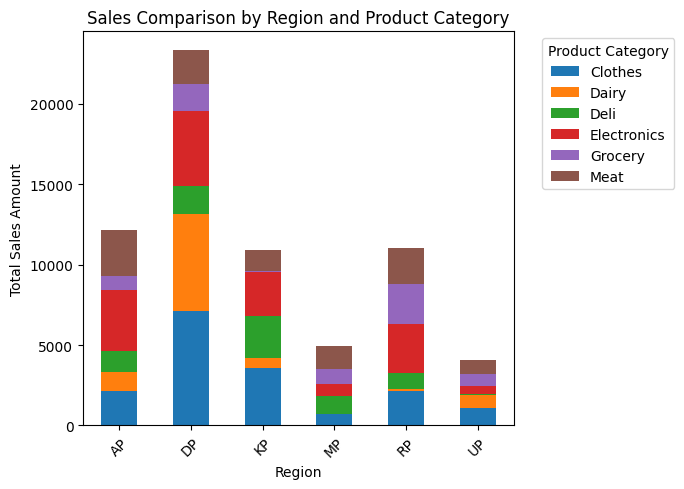

In [12]:
# 11. Stacked Bar Plot

sales_pivot.plot(
    kind='bar',
    stacked=True,
    figsize=(7,5)
)

plt.xlabel('Region')
plt.ylabel('Total Sales Amount')
plt.title('Sales Comparison by Region and Product Category')
plt.xticks(rotation=45)
plt.legend(
    title='Product Category',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

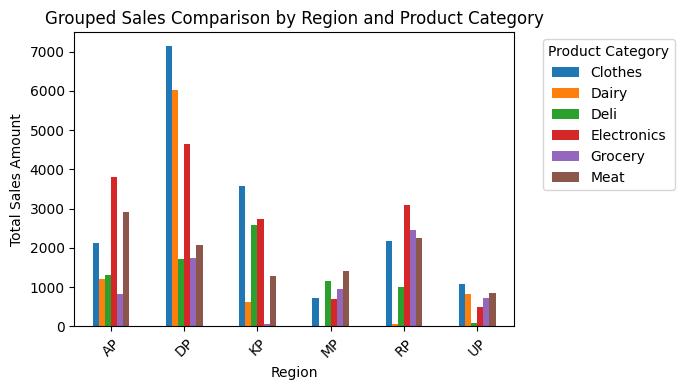

In [13]:
# 12. Grouped Bar Plot

sales_pivot.plot(
    kind='bar',
    figsize=(7,4)
)

plt.xlabel('Region')
plt.ylabel('Total Sales Amount')
plt.title('Grouped Sales Comparison by Region and Product Category')
plt.xticks(rotation=45)
plt.legend(
    title='Product Category',
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()